# KOSPI Data

In [2]:
import pandas as pd
import numpy as np

In [3]:
def detrend(series, name):
    #This function detrends the data
    series[name] = np.log(series[name])
    series = series.diff()[1:]
    return series

In [4]:
# Load data
kospi = pd.read_csv('./dat/KOSPI.csv')
kospi['Date'] = pd.to_datetime(kospi['Date'])
kospi.set_index('Date', inplace=True)
kospi = kospi.drop('Volume', axis=1)
kospi = kospi.drop('Value', axis=1)
kospi = kospi.rename(columns={'Close': 'KOSPI'})
kospi_org = kospi.copy()
kospi = detrend(kospi, 'KOSPI')

<Axes: xlabel='Date'>

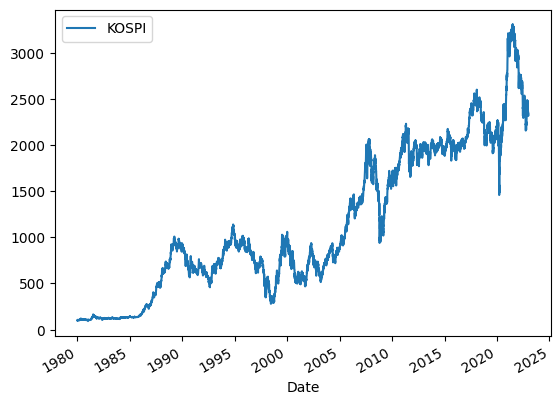

In [5]:
kospi_org.plot()

In [6]:
kospi_cp = kospi.copy()

In [7]:
def handle_missing_data(df):
    n = int(df.isna().sum())
    if n > 0:
        print(f'found {n} missing observations...')
        df.ffill(inplace=True)


def one_step_forecast(df, window):
    d = df.values
    x = []
    n = len(df)
    idx = df.index[:-window]
    for start in range(n-window):
        end = start + window
        x.append(d[start:end])
    cols = [f'x_{i}' for i in range(1, window+1)]
    x = np.array(x).reshape(n-window, -1)
    y = df.iloc[window:].values
    df_xs = pd.DataFrame(x, columns=cols, index=idx)
    df_y = pd.DataFrame(y.reshape(-1), columns=['y'], index=idx)
    print(y.reshape(-1))
    return pd.concat([df_xs, df_y], axis=1).dropna()


def split_data(df, test_split=0.15):
    n = int(len(df) * test_split)
    train, test = df[:-n], df[-n:]
    return train, test

In [8]:
handle_missing_data(kospi)

/tmp/ipykernel_3829/3334879772.py:2: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  n = int(df.isna().sum())


In [9]:
kospi_w = one_step_forecast(kospi, 10)
kospi_w.head()

[ 0.00314311 -0.00827183  0.00019775 ... -0.01843141  0.00149001
  0.00673131]


,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,x_10,y
Date,,,,,,,,,,,
1980-01-05,0.001499,0.023486,0.026468,0.010300,0.004690,-0.017462,-0.013227,-0.015167,-0.009647,0.005425,0.003143
1980-01-07,0.023486,0.026468,0.010300,0.004690,-0.017462,-0.013227,-0.015167,-0.009647,0.005425,0.003143,-0.008272
1980-01-08,0.026468,0.010300,0.004690,-0.017462,-0.013227,-0.015167,-0.009647,0.005425,0.003143,-0.008272,0.000198
1980-01-09,0.010300,0.004690,-0.017462,-0.013227,-0.015167,-0.009647,0.005425,0.003143,-0.008272,0.000198,0.005914
1980-01-10,0.004690,-0.017462,-0.013227,-0.015167,-0.009647,0.005425,0.003143,-0.008272,0.000198,0.005914,-0.001082


In [10]:
import pandas as pd
windowed_df = pd.DataFrame(columns=['Date', 'x_1', 'x_2', 'x_3', 'x_4', 'x_5', 'x_6', 'x_7', 'x_8', 'x_9', 'y'])

for i in range(7000, len(kospi)):
    row = [kospi_org.index[i]]
    for j in range(9, 0, -1):
        row.append((kospi_org.iloc[i - j]['KOSPI'] - kospi_org.iloc[i - j - 1]['KOSPI']) / (kospi_org.iloc[i - j - 1]['KOSPI']))
        #row.append(kospi.iloc[i - j]['KOSPI'])

    # Check if the price went up compared to the previous day
    pchange = (kospi_org.iloc[i]['KOSPI'] - kospi_org.iloc[i - 1]['KOSPI']) / kospi_org.iloc[i - 1]['KOSPI'] * 100
    price_up = 0
    if pchange > 0: price_up = 1
    else: price_up = 0
    #if pchange > 1.0: price_up = 2
    #elif pchange > 0.5: price_up = 1
    #elif pchange > -0.5: price_up = 0
    #elif pchange > -1.0: price_up = -1
    #else: price_up = -2
    #price_up = kospi.iloc[i]['KOSPI'] > kospi.iloc[i - 1]['KOSPI']
    row.append(price_up)

    windowed_df.loc[len(windowed_df)] = row

# Reset index of the new windowed DataFrame

windowed_df.head()

,Date,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,y
0,2004-11-04,0.009188,-0.024186,0.006880,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,0
1,2004-11-05,-0.024186,0.006880,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,1
2,2004-11-08,0.006880,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,0.011137,0
3,2004-11-09,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,0.011137,-0.016928,0
4,2004-11-10,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,0.011137,-0.016928,-0.002316,1


In [11]:
windowed_df['Date'] = pd.to_datetime(windowed_df['Date'])
windowed_df.set_index('Date', inplace=True)
windowed_df

,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,y
Date,,,,,,,,,,
2004-11-04,0.009188,-0.024186,0.006880,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,0
2004-11-05,-0.024186,0.006880,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,1
2004-11-08,0.006880,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,0.011137,0
2004-11-09,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,0.011137,-0.016928,0
2004-11-10,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,0.011137,-0.016928,-0.002316,1
...,...,...,...,...,...,...,...,...,...,...
2022-12-20,-0.004325,-0.004923,0.007575,-0.006706,-0.000261,0.011318,-0.015955,-0.000402,-0.003326,0
2022-12-21,-0.004923,0.007575,-0.006706,-0.000261,0.011318,-0.015955,-0.000402,-0.003326,-0.008027,0
2022-12-22,0.007575,-0.006706,-0.000261,0.011318,-0.015955,-0.000402,-0.003326,-0.008027,-0.001860,1


## Load S&P 500 Data

In [12]:
SPX = pd.read_csv('./dat/SPX.csv')
SPX.head()
SPX['Date'] = pd.to_datetime(SPX['Date'])
SPX.set_index('Date', inplace=True)
SPX = SPX.rename(columns={'Close': 'SPX'})
SPX = detrend(SPX, 'SPX')
SPX.head()

,SPX
Date,
1980-01-03,-0.005119
1980-01-04,0.012279
1980-01-07,0.002719
1980-01-08,0.019838
1980-01-09,0.000917


In [13]:
len(SPX)

10838

In [14]:
import pandas as pd

SPX_w = pd.DataFrame(columns=['Date', 's_1', 's_2', 's_3', 's_4', 's_5', 's_6', 's_7', 's_8', 's_9', 's_10'])

# Iterate through the original DataFrame to create the windowed dataset
for i in range(50, len(SPX)):
    row = [SPX.index[i]]
    #US/KR time difference.
    for j in range(10, 0, -1):
        row.append(SPX.iloc[i - j]['SPX'])

    SPX_w.loc[len(SPX_w)] = row

SPX_w['Date'] = pd.to_datetime(SPX_w['Date'])
SPX_w.set_index('Date', inplace=True)

SPX_w.tail()

,s_1,s_2,s_3,s_4,s_5,s_6,s_7,s_8,s_9,s_10
Date,,,,,,,,,,
2022-12-19,-0.018056,-0.014504,-0.001864,0.007494,-0.007377,0.014178,0.007263,-0.006071,-0.025237,-0.011200
2022-12-20,-0.014504,-0.001864,0.007494,-0.007377,0.014178,0.007263,-0.006071,-0.025237,-0.011200,-0.009048
2022-12-21,-0.001864,0.007494,-0.007377,0.014178,0.007263,-0.006071,-0.025237,-0.011200,-0.009048,0.001037
2022-12-22,0.007494,-0.007377,0.014178,0.007263,-0.006071,-0.025237,-0.011200,-0.009048,0.001037,0.014759
2022-12-23,-0.007377,0.014178,0.007263,-0.006071,-0.025237,-0.011200,-0.009048,0.001037,0.014759,-0.014557


In [15]:
KOSPI_SPX = pd.merge(SPX_w, windowed_df, on='Date', how='inner')
KOSPI_SPX.head()

,s_1,s_2,s_3,s_4,s_5,s_6,s_7,s_8,s_9,s_10,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,y
Date,,,,,,,,,,,,,,,,,,,,
2004-11-04,0.002561,-0.009763,-0.000858,0.014770,0.012797,0.001811,0.002445,0.000274,0.000044,0.011118,0.009188,-0.024186,0.006880,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,0
2004-11-05,-0.009763,-0.000858,0.014770,0.012797,0.001811,0.002445,0.000274,0.000044,0.011118,0.016027,-0.024186,0.006880,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,1
2004-11-08,-0.000858,0.014770,0.012797,0.001811,0.002445,0.000274,0.000044,0.011118,0.016027,0.003866,0.006880,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,0.011137,0
2004-11-09,0.014770,0.012797,0.001811,0.002445,0.000274,0.000044,0.011118,0.016027,0.003866,-0.001098,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,0.011137,-0.016928,0
2004-11-10,0.012797,0.001811,0.002445,0.000274,0.000044,0.011118,0.016027,0.003866,-0.001098,-0.000696,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,0.011137,-0.016928,-0.002316,1


## Load GC=F

In [16]:
GC = pd.read_csv('./dat/GOLDFUTURES.csv')
GC['Date'] = pd.to_datetime(GC['Date'])
GC.set_index('Date', inplace=True)
GC = GC.rename(columns={'Close': 'GC'})
GC.head()

,GC
Date,
1990-01-02,17.240000
1990-01-03,18.190001
1990-01-04,19.219999
1990-01-05,20.110001
1990-01-08,20.260000


In [17]:
import pandas as pd
GC_w = pd.DataFrame(columns=['Date', 'g_1', 'g_2', 'g_3', 'g_4', 'g_5', 'g_6', 'g_7', 'g_8', 'g_9', 'g_10'])

# Iterate through the original DataFrame to create the windowed dataset
for i in range(50, len(GC)):
    row = [GC.index[i]]
    #US/KR time difference.
    for j in range(11, 1, -1):
        row.append(GC.iloc[i - j]['GC'])

    GC_w.loc[len(GC_w)] = row

GC_w['Date'] = pd.to_datetime(GC_w['Date'])
GC_w.set_index('Date', inplace=True)

GC_w.tail()

,g_1,g_2,g_3,g_4,g_5,g_6,g_7,g_8,g_9,g_10
Date,,,,,,,,,,
2022-12-20,20.750000,22.170000,22.680000,22.290001,22.830000,25.000000,22.549999,21.139999,22.830000,22.620001
2022-12-21,22.170000,22.680000,22.290001,22.830000,25.000000,22.549999,21.139999,22.830000,22.620001,22.420000
2022-12-22,22.680000,22.290001,22.830000,25.000000,22.549999,21.139999,22.830000,22.620001,22.420000,21.480000
2022-12-23,22.290001,22.830000,25.000000,22.549999,21.139999,22.830000,22.620001,22.420000,21.480000,20.070000
2022-12-27,22.830000,25.000000,22.549999,21.139999,22.830000,22.620001,22.420000,21.480000,20.070000,21.969999


In [18]:
K_S_G = pd.merge(GC_w, KOSPI_SPX, on='Date', how='inner')
K_S_G.head()

,g_1,g_2,g_3,g_4,g_5,g_6,g_7,g_8,g_9,g_10,...,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,y
Date,,,,,,,,,,,,,,,,,,,,,
2004-11-04,14.850000,14.540000,15.280000,16.580000,16.389999,15.72,15.39,16.27,16.27,16.18,...,0.009188,-0.024186,0.006880,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,0
2004-11-05,14.540000,15.280000,16.580000,16.389999,15.720000,15.39,16.27,16.27,16.18,14.04,...,-0.024186,0.006880,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,1
2004-11-08,15.280000,16.580000,16.389999,15.720000,15.390000,16.27,16.27,16.18,14.04,13.97,...,0.006880,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,0.011137,0
2004-11-09,16.580000,16.389999,15.720000,15.390000,16.270000,16.27,16.18,14.04,13.97,13.84,...,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,0.011137,-0.016928,0
2004-11-10,16.389999,15.720000,15.390000,16.270000,16.270000,16.18,14.04,13.97,13.84,13.80,...,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,0.011137,-0.016928,-0.002316,1


## USDKRW

In [19]:
USDKRW = pd.read_csv('./dat/USDKRW.csv')
USDKRW['Date'] = pd.to_datetime(USDKRW['Date'])
USDKRW.set_index('Date', inplace=True)
USDKRW.head()

,USDKRW
Date,
1981-04-13,675.42
1981-04-14,676.73
1981-04-15,676.72
1981-04-16,676.69
1981-04-17,676.76


In [20]:
import pandas as pd

USDKRW_w = pd.DataFrame(columns=['Date', 'u_1', 'u_2', 'u_3', 'u_4', 'u_5', 'u_6', 'u_7', 'u_8', 'u_9', 'u_10'])

# Iterate through the original DataFrame to create the windowed dataset
for i in range(50, len(USDKRW)):
    row = [USDKRW.index[i]]
    #US/KR time difference.
    for j in range(11, 1, -1):
        row.append(USDKRW.iloc[i - j]['USDKRW'])

    USDKRW_w.loc[len(USDKRW_w)] = row

USDKRW_w['Date'] = pd.to_datetime(USDKRW_w['Date'])
USDKRW_w.set_index('Date', inplace=True)

USDKRW_w.tail()

,u_1,u_2,u_3,u_4,u_5,u_6,u_7,u_8,u_9,u_10
Date,,,,,,,,,,
2023-08-03,1263.85,1266.97,1284.19,1281.43,1279.30,1276.53,1277.05,1277.39,1272.86,1282.75
2023-08-04,1266.97,1284.19,1281.43,1279.30,1276.53,1277.05,1277.39,1272.86,1282.75,1295.38
2023-08-07,1284.19,1281.43,1279.30,1276.53,1277.05,1277.39,1272.86,1282.75,1295.38,1297.88
2023-08-08,1281.43,1279.30,1276.53,1277.05,1277.39,1272.86,1282.75,1295.38,1297.88,1309.21
2023-08-09,1279.30,1276.53,1277.05,1277.39,1272.86,1282.75,1295.38,1297.88,1309.21,1304.96


In [21]:
K_S_G_U = pd.merge(USDKRW_w, K_S_G, on='Date', how='inner')
K_S_G_U

,u_1,u_2,u_3,u_4,u_5,u_6,u_7,u_8,u_9,u_10,...,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,y
Date,,,,,,,,,,,,,,,,,,,,,
2004-11-04,1141.00,1140.00,1137.00,1133.00,1131.00,1126.00,1124.90,1119.00,1120.00,1112.50,...,0.009188,-0.024186,0.006880,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,0
2004-11-05,1140.00,1137.00,1133.00,1131.00,1126.00,1124.90,1119.00,1120.00,1112.50,1113.00,...,-0.024186,0.006880,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,1
2004-11-08,1137.00,1133.00,1131.00,1126.00,1124.90,1119.00,1120.00,1112.50,1113.00,1111.00,...,0.006880,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,0.011137,0
2004-11-09,1133.00,1131.00,1126.00,1124.90,1119.00,1120.00,1112.50,1113.00,1111.00,1110.00,...,-0.004658,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,0.011137,-0.016928,0
2004-11-10,1131.00,1126.00,1124.90,1119.00,1120.00,1112.50,1113.00,1111.00,1110.00,1107.00,...,0.029176,0.001560,0.000982,0.013175,0.016984,-0.011440,0.011137,-0.016928,-0.002316,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-12-19,1300.21,1292.31,1315.45,1317.23,1319.26,1301.07,1308.64,1301.57,1294.24,1301.89,...,-0.010813,-0.004325,-0.004923,0.007575,-0.006706,-0.000261,0.011318,-0.015955,-0.000402,0
2022-12-20,1292.31,1315.45,1317.23,1319.26,1301.07,1308.64,1301.57,1294.24,1301.89,1308.40,...,-0.004325,-0.004923,0.007575,-0.006706,-0.000261,0.011318,-0.015955,-0.000402,-0.003326,0
2022-12-21,1315.45,1317.23,1319.26,1301.07,1308.64,1301.57,1294.24,1301.89,1308.40,1302.62,...,-0.004923,0.007575,-0.006706,-0.000261,0.011318,-0.015955,-0.000402,-0.003326,-0.008027,0


## Do Actual Bits

In [22]:
import pandas as pd
class Standardise:
    def __init__(self, df, split=0.10):
        self.data = df.copy()
        self.split = split

    def split_data(self):
        portion_size = len(self.data) // 5
        a_size = int(portion_size * 0.7)
        b_size = int(portion_size * 0.2)
        c_size = portion_size - a_size - b_size

        dataframes = []
        for i in range(5):
            start_idx = i * portion_size
            end_idx = (i + 1) * portion_size

            a_end_idx = start_idx + a_size
            b_end_idx = a_end_idx + b_size

            df_a = self.data.iloc[start_idx:a_end_idx]
            df_b = self.data.iloc[a_end_idx:b_end_idx]
            df_c = self.data.iloc[b_end_idx:end_idx]

            dataframes.extend([df_a, df_b, df_c])

        df_a = pd.concat(dataframes[::3], ignore_index=True)
        df_b = pd.concat(dataframes[1::3], ignore_index=True)
        df_c = pd.concat(dataframes[2::3], ignore_index=True)

        return df_a, df_b, df_c

    def _transform(self, data):
        data_s = data.copy()
        for column in data_s.columns:
            if column == 'y':
                continue
            # Apply Z-score standardization using training statistics
            data_s[column] = (data_s[column] - self.mu[column]) / (self.sigma[column] + 1e-8)
        return data_s

    def fit_transform(self):
        train, test, val = self.split_data()
        # Calculate mean and standard deviation from the training set
        self.mu = train.mean()
        self.sigma = train.std()

        train_s = self._transform(train)
        test_s = self._transform(test)
        val_s = self._transform(val)
        return train_s, test_s, val_s

    def inverse(self, data):
        return (data * self.sigma) + self.mu

    def inverse_y(self, data):
        return (data * self.sigma[-1]) + self.mu[-1]

In [23]:
scale_en = Standardise(K_S_G_U)
train_en, test_en, val_en = scale_en.fit_transform()
train_en[6:30]

,u_1,u_2,u_3,u_4,u_5,u_6,u_7,u_8,u_9,u_10,...,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,y
6,0.030722,-0.027150,-0.015711,-0.090032,-0.083519,-0.102290,-0.110829,-0.140160,-0.189379,-0.087799,...,0.035930,1.027143,1.333180,-0.971027,0.859347,-1.417065,-0.226161,1.534674,0.032876,1
7,-0.028632,-0.017094,-0.091136,-0.085007,-0.103624,-0.112334,-0.140969,-0.190350,-0.089047,-0.097832,...,1.023285,1.336057,-0.981243,0.864629,-1.425380,-0.227754,1.533569,0.019445,1.425910,1
8,-0.018572,-0.092515,-0.086108,-0.105109,-0.113676,-0.142468,-0.191203,-0.089971,-0.099080,-0.208194,...,1.331725,-0.969151,0.857086,-1.417319,-0.235871,1.541113,0.029158,1.410418,0.491857,0
9,-0.094021,-0.087487,-0.106221,-0.115160,-0.143833,-0.192690,-0.090735,-0.100009,-0.209446,-0.253342,...,-0.969949,0.861858,-1.428186,-0.229257,1.533291,0.028892,1.410200,0.477747,-0.564950,1
10,-0.088991,-0.107600,-0.116278,-0.145313,-0.194094,-0.092245,-0.100782,-0.210426,-0.254595,-0.298490,...,0.858254,-1.414314,-0.238393,1.537753,0.020817,1.417104,0.484188,-0.577496,0.785385,0
11,-0.109110,-0.117656,-0.146448,-0.195569,-0.093571,-0.102290,-0.211296,-0.255596,-0.299745,-0.408853,...,-1.414429,-0.229258,1.531191,0.027119,1.409261,0.486284,-0.563521,0.770841,-0.919168,0
12,-0.119170,-0.147824,-0.196731,-0.095058,-0.103624,-0.212779,-0.256507,-0.300766,-0.410110,-0.519215,...,-0.231190,1.533279,0.018357,1.413874,0.478286,-0.566865,0.775189,-0.931190,-0.857028,0
13,-0.149350,-0.198106,-0.096164,-0.105109,-0.214199,-0.257979,-0.301717,-0.411183,-0.520476,-0.529248,...,1.528645,0.026469,1.407131,0.484031,-0.575038,0.778796,-0.914689,-0.869142,-1.640655,1
14,-0.199649,-0.097543,-0.106221,-0.215671,-0.259434,-0.303179,-0.412232,-0.521600,-0.530509,-0.579412,...,0.024145,1.409714,0.475934,-0.568012,0.770846,-0.919856,-0.853085,-1.651609,0.964836,1
15,-0.109110,-0.218218,-0.262099,-0.306131,-0.415245,-0.524157,-0.532793,-0.581827,-0.570642,-0.559346,...,0.479202,-0.567156,0.768565,-0.920633,-0.866154,-1.638846,0.953096,1.103819,-0.042013,0


In [24]:
KOSPI_SPX['s_1'].std()

0.012513691703843699

In [25]:
def features_target_ts_reshaped(*args):
    y_list = []
    x_list = []
    for df in args:
        df_cp = df.copy()
        y_val = df_cp.pop('y').values.reshape(-1, 1)
        y_list.append(y_val)

        # Features extraction
        u = df_cp[[f'u_{i}' for i in range(1, 11)]].values # (N, 10)
        g = df_cp[[f'g_{i}' for i in range(1, 11)]].values # (N, 10)
        s = df_cp[[f's_{i}' for i in range(1, 11)]].values # (N, 10)
        # KOSPI only has 9 lag features (x_1 to x_9), we pad with 0 for the first timestep to make it 10
        x = df_cp[[f'x_{i}' for i in range(1, 10)]].values # (N, 9)
        x_padded = np.hstack([np.zeros((x.shape[0], 1)), x]) # (N, 10)

        # Stack features as variables across 10 timesteps: shape (N, 10, 4)
        # Dimensions: [Samples, Timesteps (10), Features (USD/KRW, Gold, SPX, KOSPI)]
        x_multivariate = np.stack([u, g, s, x_padded], axis=-1)
        x_list.append(x_multivariate)

    return *y_list, *x_list

In [26]:
from tensorflow.keras import Sequential
from tensorflow import keras
from keras.layers import LSTM, Dense, Activation, Dropout, Reshape
from tensorflow.keras.layers import BatchNormalization
from keras.regularizers import l2
from tensorflow.keras.metrics import *

# Re-extract datasets with multivariate 3D shape
(y_train_en, y_val_en, y_test_en, x_train_en, x_val_en, x_test_en) = features_target_ts_reshaped(train_en, val_en, test_en)

# Convert targets to categorical labels
y_train_en = keras.utils.to_categorical(y_train_en, num_classes=2)
y_val_en = keras.utils.to_categorical(y_val_en, num_classes=2)
y_test_en = keras.utils.to_categorical(y_test_en, num_classes=2)

print("New Train Features Shape:", x_train_en.shape)
print("New Train Target Shape:", y_train_en.shape)

New Train Features Shape: (3045, 10, 4)
New Train Target Shape: (3045, 2)


In [27]:
def create_multivariate_model(train_shape, lstm_memory=64, dropout_rate=0.2):
    model = Sequential()
    # Explicitly state the input shape (10 timesteps, 4 features) using Input layer
    model.add(keras.layers.Input(shape=(train_shape[1], train_shape[2])))
    model.add(LSTM(lstm_memory, return_sequences=False))
    model.add(Dropout(dropout_rate))
    model.add(Dense(64, activation='relu'))
    model.add(Dense(32, activation='relu', kernel_regularizer=l2(0.01)))
    model.add(Dense(1, activation='sigmoid'))
    return model

In [28]:
def train_model_ts(model,
                x_train, y_train, x_val, y_val,
                epochs=500,
                patience=12,
                batch_size=32):

    # Using binary_crossentropy and BinaryAccuracy metric
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999),
                  loss='binary_crossentropy',
                  metrics=[BinaryAccuracy()]
    )

    es = keras.callbacks.EarlyStopping(
                    monitor="val_loss",
                    min_delta=0,
                    patience=patience)

    history = model.fit(x_train, y_train,
              shuffle=False, epochs=epochs,
              batch_size=batch_size,
              validation_data=(x_val, y_val),
              callbacks=[es], verbose=1)
    return history

In [29]:
def plot_forecast(model, x_test, y_test, index, history):
    fig, ax = plt.subplots(2, 1)
    (pd.Series(history.history['loss'])
                      .plot(style='k',alpha=0.50, title='Loss by Epoch',
                            ax = ax[0], label='loss'))
    (pd.Series(history.history['val_loss'])
                      .plot(style='k',ax=ax[0],label='val_loss'))
    ax[0].legend()
    predicted = model.predict(x_test)
    pd.Series(y_test.reshape(-1),
              index=index).plot(style='k--', alpha=0.5, ax=ax[1],
                                title='Forecast vs Actual',
                                label='actual')
    pd.Series(predicted.reshape(-1),
              index=index).plot(
            style='k',label='Forecast', ax=ax[1])
    fig.tight_layout()
    ax[1].legend()
    plt.show()

In [30]:
scale_en = Standardise(K_S_G_U)
train_en, test_en, val_en = scale_en.fit_transform()

(y_train_en, y_val_en, y_test_en, x_train_en, x_val_en, x_test_en) = features_target_ts_reshaped(train_en, val_en, test_en)

print("Features shape:", x_train_en.shape)
print("Targets shape:", y_train_en.shape)

Features shape: (3045, 10, 4)
Targets shape: (3045, 1)


In [31]:
model_en_lstm = create_multivariate_model(x_train_en.shape, dropout_rate=0.2)
model_en_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,937 (93.50 KB)

 Trainable params: 23,937 (93.50 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
history_en_lstm_dropout = train_model_ts(
    model_en_lstm,
    x_train_en,
    y_train_en,
    x_val_en,
    y_val_en,
    epochs=100,
    patience=10,
    batch_size=32
)

Epoch 1/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - binary_accuracy: 0.5478 - loss: 0.9417 - val_binary_accuracy: 0.5333 - val_loss: 0.8218
Epoch 2/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - binary_accuracy: 0.5954 - loss: 0.7494 - val_binary_accuracy: 0.5839 - val_loss: 0.7116
Epoch 3/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - binary_accuracy: 0.6141 - loss: 0.6822 - val_binary_accuracy: 0.5885 - val_loss: 0.6676
Epoch 4/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - binary_accuracy: 0.6246 - loss: 0.6598 - val_binary_accuracy: 0.5931 - val_loss: 0.6596
Epoch 5/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - binary_accuracy: 0.6263 - loss: 0.6537 - val_binary_accuracy: 0.5954 - val_loss: 0.6681
Epoch 6/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - binary_accuracy: 0.6253 - loss: 0.6481 - val_binary_accuracy: 0.5931 - val_loss: 0.6748
Epoch 7/100
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - binary_accuracy: 0.6365 - loss: 0.6468 - val_binary_accuracy: 0.5839 - val_loss: 0.6816
Epoch 8/

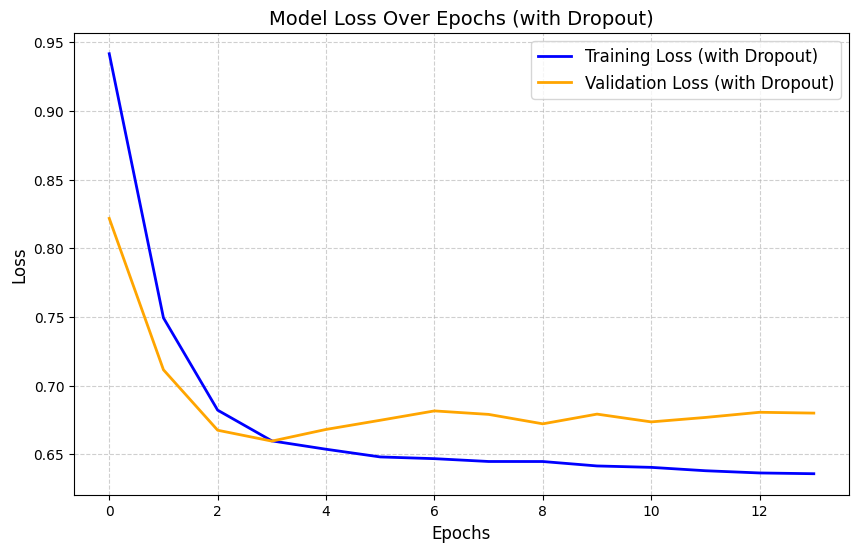

In [33]:
import matplotlib.pyplot as plt

# Plot the training and validation loss curves with dropout
plt.figure(figsize=(10, 6))
plt.plot(history_en_lstm_dropout.history['loss'], label='Training Loss (with Dropout)', color='blue', linewidth=2)
plt.plot(history_en_lstm_dropout.history['val_loss'], label='Validation Loss (with Dropout)', color='orange', linewidth=2)
plt.title('Model Loss Over Epochs (with Dropout)', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [34]:
# Evaluate the performance on the test set
test_loss, test_accuracy = model_en_lstm.evaluate(x_test_en, y_test_en)
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_accuracy:.4f}')

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - binary_accuracy: 0.6299 - loss: 0.6425
Test Loss: 0.6425
Test Accuracy: 0.6299


In [35]:
prediction = model_en_lstm.predict(x_test_en)

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


In [36]:
prediction[1:100]

array([[0.7404114 ],
       [0.551175  ],
       [0.72573113],
       [0.58693177],
       [0.5715049 ],
       [0.35871553],
       [0.67891943],
       [0.59859776],
       [0.735389  ],
       [0.557724  ],
       [0.67309654],
       [0.59600675],
       [0.45404887],
       [0.24248192],
       [0.7794573 ],
       [0.56021196],
       [0.37306616],
       [0.83626   ],
       [0.6104238 ],
       [0.68358237],
       [0.4733655 ],
       [0.58848286],
       [0.30114797],
       [0.69110197],
       [0.31982306],
       [0.6277452 ],
       [0.56764996],
       [0.81937695],
       [0.5634409 ],
       [0.49083802],
       [0.6251574 ],
       [0.45852327],
       [0.5100464 ],
       [0.59905565],
       [0.58531684],
       [0.3714885 ],
       [0.71885747],
       [0.7840695 ],
       [0.60124856],
       [0.64369315],
       [0.5900235 ],
       [0.6867387 ],
       [0.3066985 ],
       [0.70865107],
       [0.18407822],
       [0.68661255],
       [0.17946781],
       [0.416

## Trading simulation using the model

Here we backtest the model's performance and compare it against the simple Buy&Hold strategy. In the backtest, we use the following strategy:
* We always have 100% cash or 100% stock (KOSPI ETF).
* If the model predicts bull:
  * If we currently have cash, buy it.
  * If we currently have stock, keep it.
* If the model predicts bear:
  * If we currently have cash, keep it.
  * If we currently have stock, sell it.
 Results show that we can gain 4%p-12%p alpha using the strategy over the five different 8-month testing period.

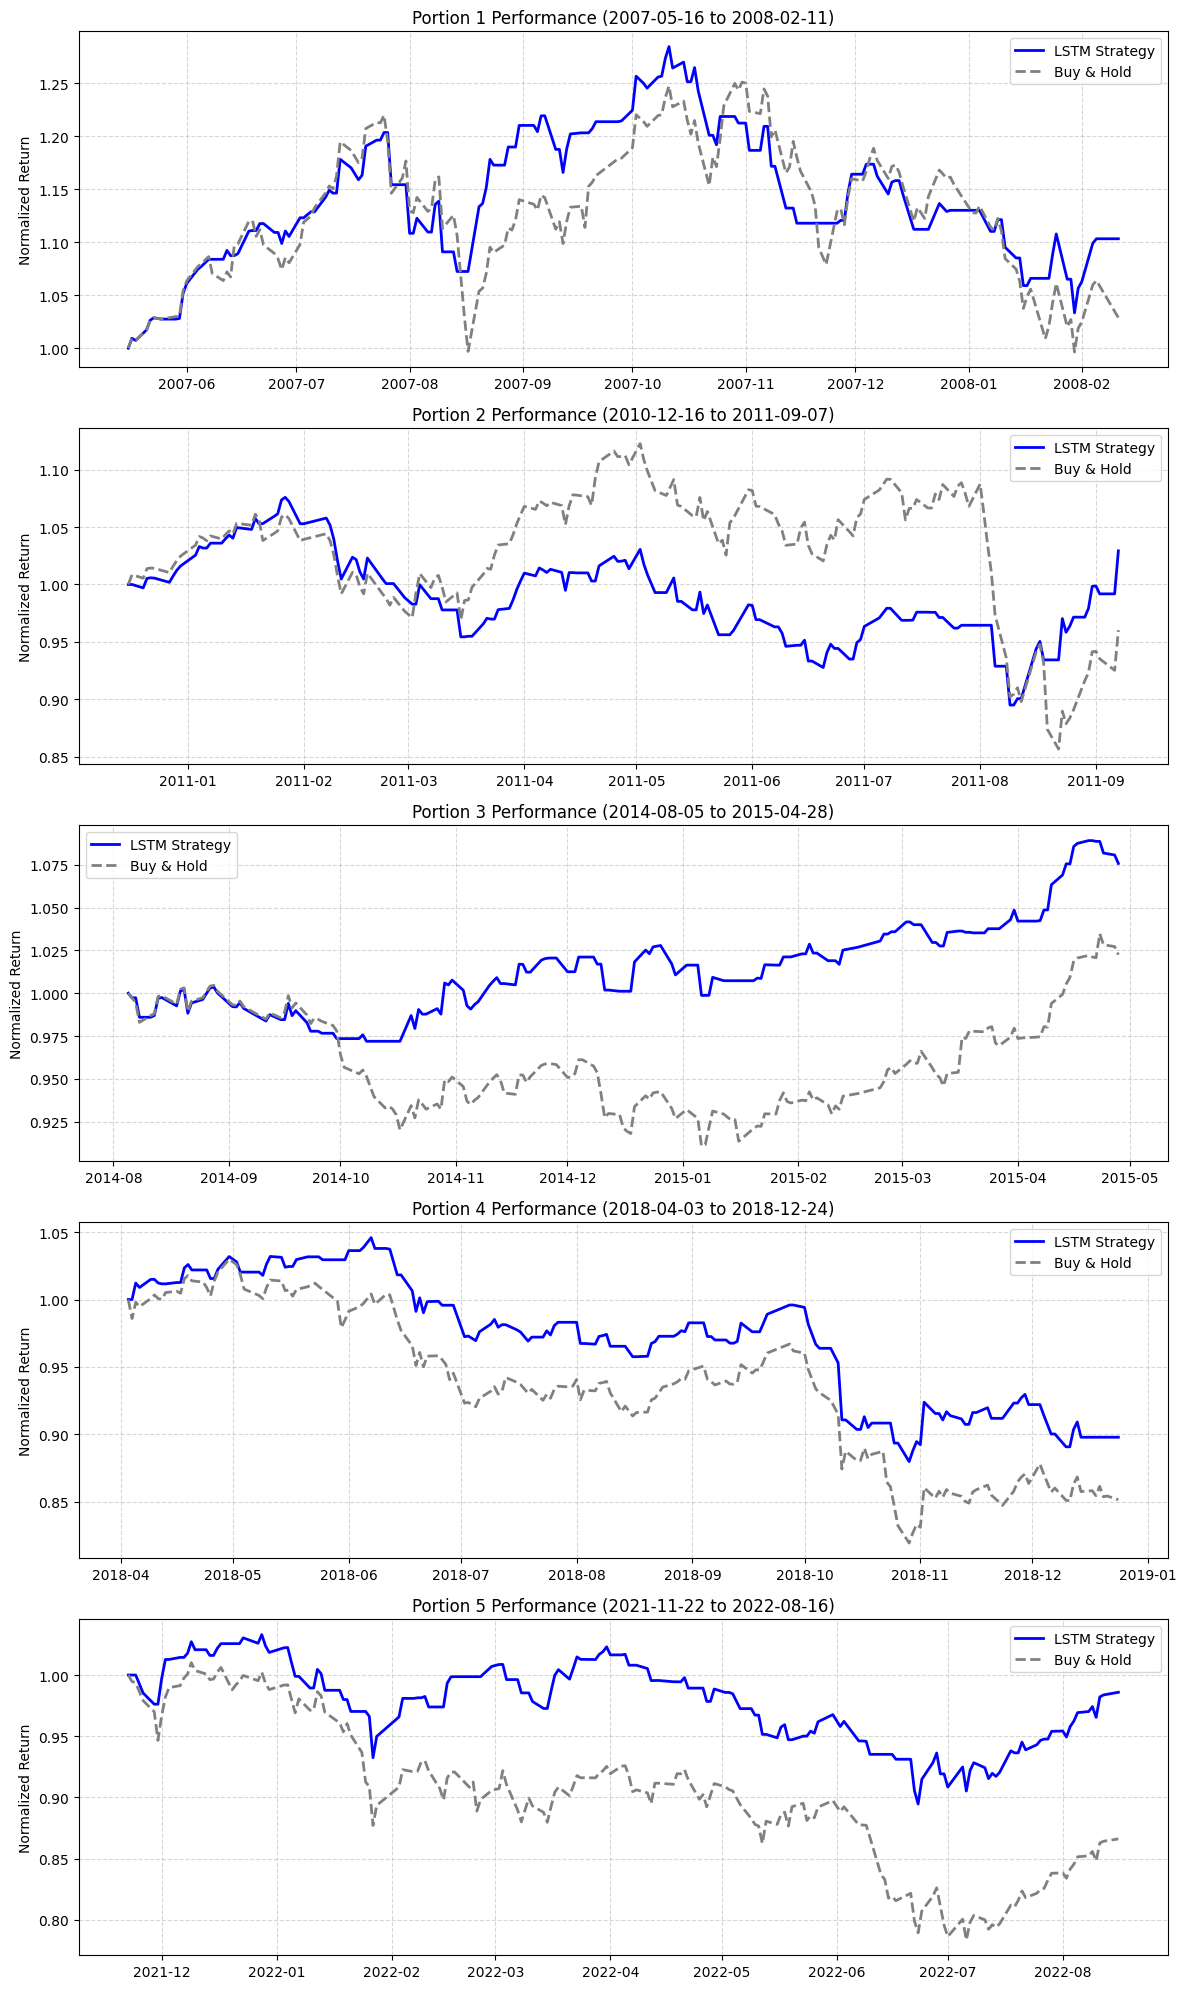

,Portion,Start Date,End Date,Buy & Hold Final Return,LSTM Strategy Final Return,Outperformance (LSTM - B&H)
0,Portion 1,2007-05-16,2008-02-11,1.0288,1.1033,0.0745
1,Portion 2,2010-12-16,2011-09-07,0.9601,1.0293,0.0692
2,Portion 3,2014-08-05,2015-04-28,1.0225,1.0758,0.0532
3,Portion 4,2018-04-03,2018-12-24,0.8516,0.8979,0.0463
4,Portion 5,2021-11-22,2022-08-16,0.8662,0.9859,0.1198


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reconstruct the exact segments
portion_size = len(K_S_G_U) // 5
a_size = int(portion_size * 0.7)
b_size = int(portion_size * 0.2)

# Initialize lists to store comparison statistics dynamically
portions = []
start_dates = []
end_dates = []
final_bh = []
final_lstm = []
outperformance = []

fig, axes = plt.subplots(5, 1, figsize=(12, 20))
signals_all = (prediction.reshape(-1) > 0.5).astype(int)

for i in range(5):
    start_idx = i * portion_size
    a_end_idx = start_idx + a_size
    b_end_idx = a_end_idx + b_size

    # Segment dates & actual daily returns
    segment_dates = K_S_G_U.index[a_end_idx:b_end_idx]
    actual_returns = kospi_org['KOSPI'].pct_change().loc[segment_dates].values

    # Map corresponding predictions for this segment
    seg_start_pred = i * b_size
    seg_end_pred = (i + 1) * b_size
    segment_signals = signals_all[seg_start_pred:seg_end_pred]

    wealth_strategy = []
    wealth_bh = []

    for step in range(len(segment_dates)):
        current_return = actual_returns[step]

        if step == 0:
            wealth_strategy.append(1.0)
            wealth_bh.append(1.0)
        else:
            # Buy & Hold benchmark
            wealth_bh.append(wealth_bh[-1] * (1 + current_return))

            # Strategy based on previous day's signal
            prev_signal = segment_signals[step - 1]
            if prev_signal == 1:
                new_wealth = wealth_strategy[-1] * (1 + current_return)
            else:
                new_wealth = wealth_strategy[-1]

            wealth_strategy.append(new_wealth)

    # Plotting
    ax = axes[i]
    ax.plot(segment_dates, wealth_strategy, label='LSTM Strategy', color='blue', linewidth=2)
    ax.plot(segment_dates, wealth_bh, label='Buy & Hold', color='gray', linestyle='--', linewidth=2)
    ax.set_title(f'Portion {i+1} Performance ({segment_dates[0].strftime("%Y-%m-%d")} to {segment_dates[-1].strftime("%Y-%m-%d")})')
    ax.set_ylabel('Normalized Return')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)

    # Dynamically record stats inside the same loop to avoid redundant recalculation
    portions.append(f"Portion {i+1}")
    start_dates.append(segment_dates[0].strftime("%Y-%m-%d"))
    end_dates.append(segment_dates[-1].strftime("%Y-%m-%d"))
    final_bh.append(wealth_bh[-1])
    final_lstm.append(wealth_strategy[-1])
    outperformance.append(wealth_strategy[-1] - wealth_bh[-1])

plt.tight_layout()
plt.show()

# Create a performance summary DataFrame directly from the collected values
summary_df = pd.DataFrame({
    'Portion': portions,
    'Start Date': start_dates,
    'End Date': end_dates,
    'Buy & Hold Final Return': final_bh,
    'LSTM Strategy Final Return': final_lstm,
    'Outperformance (LSTM - B&H)': outperformance
})

pd.options.display.float_format = '{:,.4f}'.format
display(summary_df)